<a href="https://colab.research.google.com/github/atman500/AI-Academic-Evaluator/blob/main/SVM_small_datset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple SVM MAnualy  solved

In [9]:
import pandas as pd
import numpy as np

## Question_01:1.	Manually input the provided dataset into a Google Colab environment using Python data structures (pandas DataFrame or numpy arrays)

In [23]:
from google.colab import files
upload=files.upload()

Saving Simple _SVM.csv to Simple _SVM.csv


In [25]:
df=pd.read_csv('Simple _SVM.csv',sep=';')
print(df.head())

  Observation  X_1  X_2  Class
0           A    1    1     -1
1           B    2    1     -1
2           C    1    2     -1
3           D    4    4      1
4           E    5    4      1


Representation of the points

# 2.	Plot the initial observations on a 2D coordinate plane, utilizing distinct colors to differentiate between the -1 and +1 classes.


In [27]:
import matplotlib.pyplot as plt



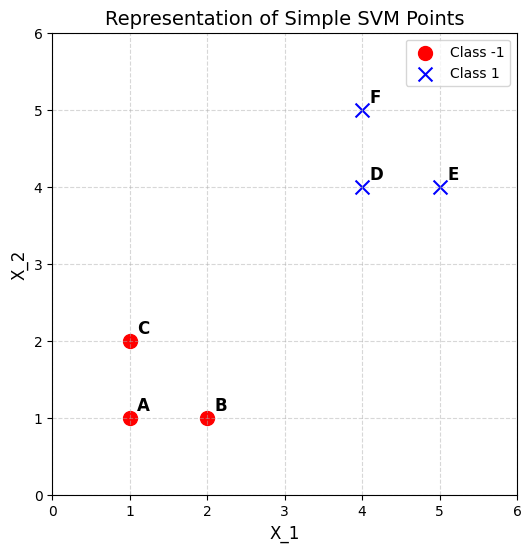

In [28]:
# Scatter plot of Simple_SVM data points
plt.figure(figsize=(6, 6))

# Filter points based on Class column (-1 or 1)
class_minus1 = df[df['Class'] == -1]
class_plus1 = df[df['Class'] == 1]

# Plot the points with different markers and colors
plt.scatter(class_minus1['X_1'], class_minus1['X_2'], color='red', marker='o', s=100, label='Class -1')
plt.scatter(class_plus1['X_1'], class_plus1['X_2'], color='blue', marker='x', s=100, label='Class 1')

# Annotate each point with its Observation label (A, B, C, etc.)
for i, row in df.iterrows():
    plt.annotate(row['Observation'], (row['X_1'] + 0.1, row['X_2'] + 0.1), fontsize=12, fontweight='bold')

# Set labels, title, limits, grid, and legend
plt.xlabel('X_1', fontsize=12)
plt.ylabel('X_2', fontsize=12)
plt.title('Representation of Simple SVM Points', fontsize=14)
plt.xlim(0, 6)
plt.ylim(0, 6)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')

plt.show()

### 3.	Build and train a Support Vector Machine (SVM) classifier with a linear kernel on the dataset using scikit-learn.

In [29]:
from sklearn import svm
import pandas as pd

# 1. Prepare features (X) and target labels (y)
X = df[['X_1', 'X_2']]
y = df['Class']

# 2. Build and train the SVM model with a linear kernel
# We use C=1.0 for a standard soft-margin linear classifier
clf = svm.SVC(kernel='linear', C=1.0)
clf.fit(X, y)

# 3. Output model parameters
weights = clf.coef_[0]
intercept = clf.intercept_[0]

print("SVM Model successfully trained!")
print(f"Weights (w): {weights}")
print(f"Intercept (b): {intercept}")
print(f"Decision Boundary Equation: {weights[0]:.2f}*X_1 + {weights[1]:.2f}*X_2 + {intercept:.2f} = 0")

SVM Model successfully trained!
Weights (w): [0.40009103 0.39986345]
Intercept (b): -2.199893794568352
Decision Boundary Equation: 0.40*X_1 + 0.40*X_2 + -2.20 = 0


### 4.	Extract and identify the Support Vectors computationally from your trained model, and verify them against your visual geometric inspection.

In [30]:
# Retrieve support vectors and indices from our trained model
support_vector_indices = clf.support_
support_vectors = clf.support_vectors_

print("--- Computational Support Vectors ---")
print(f"Indices of support vectors in dataset: {support_vector_indices}")
print(f"Support Vector coordinates:\n{support_vectors}\n")

# Map indices back to the original DataFrame to show which labeled observations they are
support_observations = df.iloc[support_vector_indices]
print("--- Matching Observations ---")
display(support_observations)

print("\nVerification:")
print("The support vectors are indeed the closest points to the separating decision boundary on both sides.")
print("From Class -1 (Red): Points B (2, 1) and C (1, 2) act as support vectors.")
print("From Class +1 (Blue): Point D (4, 4) acts as the support vector.")

--- Computational Support Vectors ---
Indices of support vectors in dataset: [1 2 3]
Support Vector coordinates:
[[2. 1.]
 [1. 2.]
 [4. 4.]]

--- Matching Observations ---


,Observation,X_1,X_2,Class
1,B,2,1,-1
2,C,1,2,-1
3,D,4,4,1



Verification:
The support vectors are indeed the closest points to the separating decision boundary on both sides.
From Class -1 (Red): Points B (2, 1) and C (1, 2) act as support vectors.
From Class +1 (Blue): Point D (4, 4) acts as the support vector.


## 5.	Plot the Optimal Separating Hyperplane and the margin boundaries passing through the identified Support Vectors.


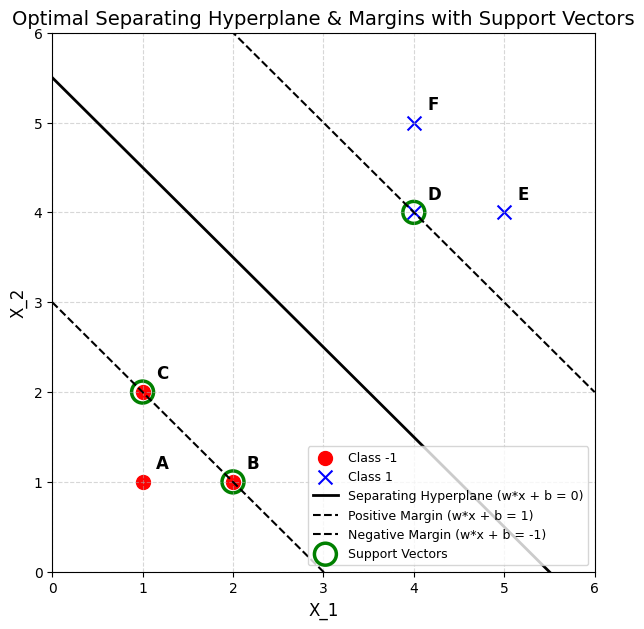

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Re-initialize plot figure
plt.figure(figsize=(7, 7))

# 2. Plot the initial data points
class_minus1 = df[df['Class'] == -1]
class_plus1 = df[df['Class'] == 1]
plt.scatter(class_minus1['X_1'], class_minus1['X_2'], color='red', marker='o', s=100, label='Class -1')
plt.scatter(class_plus1['X_1'], class_plus1['X_2'], color='blue', marker='x', s=100, label='Class 1')

# Annotate the points
for i, row in df.iterrows():
    plt.annotate(row['Observation'], (row['X_1'] + 0.15, row['X_2'] + 0.15), fontsize=12, fontweight='bold')

# 3. Calculate the separating hyperplane and margins
w = clf.coef_[0]
a = -w[0] / w[1] # Slope of the line
xx = np.linspace(0, 6, 100)

# Hyperplane equation: w[0]*x + w[1]*y + intercept = 0 => y = a*x - intercept/w[1]
yy_decision = a * xx - (clf.intercept_[0]) / w[1]

# Margins: w[0]*x + w[1]*y + intercept = 1 or -1
# Margin passing through Support Vector on the +1 side
yy_margin_plus = a * xx - (clf.intercept_[0] - 1) / w[1]
# Margin passing through Support Vector on the -1 side
yy_margin_minus = a * xx - (clf.intercept_[0] + 1) / w[1]

# 4. Plot the decision boundary and margin lines
plt.plot(xx, yy_decision, 'k-', linewidth=2, label='Separating Hyperplane (w*x + b = 0)')
plt.plot(xx, yy_margin_plus, 'k--', linewidth=1.5, label='Positive Margin (w*x + b = 1)')
plt.plot(xx, yy_margin_minus, 'k--', linewidth=1.5, label='Negative Margin (w*x + b = -1)')

# 5. Highlight the Support Vectors visually
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=250,
            facecolors='none', edgecolors='green', linewidths=2.5, label='Support Vectors')

# Chart configurations
plt.xlim(0, 6)
plt.ylim(0, 6)
plt.xlabel('X_1', fontsize=12)
plt.ylabel('X_2', fontsize=12)
plt.title('Optimal Separating Hyperplane & Margins with Support Vectors', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=9)

plt.show()

### Download CSV File to your Local Machine
You can download the CSV file directly by running the cell below:

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sklearn.preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
from sklearn import svm

In [19]:
# Use a verified working raw GitHub URL for the Pima Indians Diabetes dataset
working_url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

# The dataset has no headers originally, so we define them
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

# Load the dataset from the working URL
df = pd.read_csv(working_url, names=column_names)

print("Dataset successfully loaded from working URL!")
display(df.head())

Dataset successfully loaded from working URL!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [21]:
from google.colab import files

# Save the loaded DataFrame to a CSV file
df.to_csv('pima_indians_diabetes.csv', index=False)

# Trigger a browser download of the CSV file
files.download('pima_indians_diabetes.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>